# 06. Model 2: CatBoost Classifier

**Employee Resignation Prediction Project**  
**Ownership:** Member 2  
**Architecture:** Gradient Boosted Decision Trees with Ordered Boosting & Native Categorical Handling  
**Status:** IMPLEMENTED & VALIDATED

## 1. Objective

Implement, tune, and evaluate **CatBoost** on the 5-fold cross-validation development set (80,000 records). CatBoost utilizes ordered target statistics and symmetric trees to reduce target leakage and handle categorical features natively.

## 2. Reproducibility

Configure deterministic seeds (`random_seed=42`), dynamic path resolution, and multithreaded evaluation settings.

In [18]:
import sys
import time
import hashlib
import json
from pathlib import Path

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier, Pool

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Resolve repository root
PROJECT_ROOT = Path("../..").resolve()
if not (PROJECT_ROOT / "configs" / "feature_contract.yaml").exists():
    for candidate in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        if (candidate / "configs" / "feature_contract.yaml").exists():
            PROJECT_ROOT = candidate.resolve()
            break

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Project configurations and paths
CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "catboost.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
SPLIT_REGISTRY_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"

MODELS_DIR = PROJECT_ROOT / "models" / "catboost"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "catboost"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

def sha256_file(file_path: Path) -> str:
    """Compute SHA-256 hash of a file."""
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

print(f"Project Root: {PROJECT_ROOT}")
print(f"Models Directory: {MODELS_DIR}")
print(f"Results Directory: {RESULTS_DIR}")

Project Root: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project
Models Directory: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\models\catboost
Results Directory: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\models\catboost


## 3. Load Development Registry

Load `split_registry.csv` and filter strictly to `partition == 'development'`. Ensure the 20,000 formal holdout records remain strictly quarantined.

In [19]:
assert RAW_DATA_PATH.exists(), f"Raw data not found at {RAW_DATA_PATH}"
assert SPLIT_REGISTRY_PATH.exists(), f"Split registry not found at {SPLIT_REGISTRY_PATH}"

raw_df = pd.read_csv(RAW_DATA_PATH)
split_registry = pd.read_csv(SPLIT_REGISTRY_PATH, dtype={"cv_fold": "Int64"})

# Verify 1-to-1 merge
merged_df = raw_df.merge(split_registry, on="Employee_ID", how="inner", validate="one_to_one")
assert len(merged_df) == len(raw_df), "Mismatch during dataset and split registry merge."

# Strictly isolate 80,000 development rows
dev_df = merged_df.loc[merged_df["partition"] == "development"].copy().reset_index(drop=True)
assert len(dev_df) == 80_000, f"Expected 80,000 dev rows, got {len(dev_df)}"

# Store holdout IDs for leakage assertions
holdout_ids = set(split_registry.loc[split_registry["partition"] == "holdout", "Employee_ID"])
assert len(holdout_ids) == 20_000, f"Expected 20,000 holdout IDs, got {len(holdout_ids)}"

fold_counts = dev_df["cv_fold"].value_counts().sort_index()
print(f"Development partition loaded: {len(dev_df):,} rows")
print(f"Quarantined holdout rows: {len(holdout_ids):,}")
print("Development CV fold distributions:\n" + fold_counts.to_string())

Development partition loaded: 80,000 rows
Quarantined holdout rows: 20,000
Development CV fold distributions:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000


## 4. Validate Feature Contract

Confirm the 17 approved predictors (4 categorical, 13 numerical) match `configs/feature_contract.yaml` exactly.

In [20]:
assert FEATURE_CONTRACT_PATH.exists(), f"Feature contract missing at: {FEATURE_CONTRACT_PATH}"

with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as f:
    contract = yaml.safe_load(f)

assert contract["contract"]["status"] == "frozen", "Feature contract must be frozen before training."

target_column = contract["target"]["column"]
positive_class = contract["target"]["positive_class"]
negative_class = contract["target"]["negative_class"]

categorical_features = [item["name"] for item in contract["categorical_features"]]
numerical_features = [item["name"] for item in contract["numerical_features"]]
primary_features = contract["primary_model_features"]
excluded_features = [item["column"] for item in contract["excluded_features"]]

assert len(categorical_features) == 4, f"Expected 4 categorical features, found {len(categorical_features)}"
assert len(numerical_features) == 13, f"Expected 13 numerical features, found {len(numerical_features)}"
assert len(primary_features) == 17, f"Expected 17 primary features, found {len(primary_features)}"
assert target_column == "Resigned" and positive_class is True

print("Feature contract validated:")
print(f"  Categorical ({len(categorical_features)}): {categorical_features}")
print(f"  Numerical ({len(numerical_features)}): {numerical_features}")
print(f"  Target: {target_column} (positive={positive_class})")

Feature contract validated:
  Categorical (4): ['Department', 'Gender', 'Job_Title', 'Education_Level']
  Numerical (13): ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
  Target: Resigned (positive=True)


## 5. Model-Specific Preprocessing

CatBoost natively consumes categorical features via `cat_features` indices without external one-hot encoding. Features are cast to strings, and the target is mapped to a binary integer (`True` $\rightarrow$ 1, `False` $\rightarrow$ 0).

In [21]:
# Format categorical predictors as strings for native handling
for col in categorical_features:
    dev_df[col] = dev_df[col].astype(str)

# Map target to integer
dev_df["target"] = dev_df[target_column].astype(int)

# Verify no nulls in predictors or target
assert not dev_df[primary_features].isna().any().any(), "Missing values found in primary features."
assert not dev_df["target"].isna().any(), "Missing values found in target."

print("Target distribution in development partition:")
print(dev_df["target"].value_counts().to_string())
print(f"Positive prevalence: {dev_df['target'].mean() * 100:.2f}%")

Target distribution in development partition:
target
0    71992
1     8008
Positive prevalence: 10.01%


## 6. Hyperparameter Search Space

Load search space bounds from `configs/models/catboost.yaml` (iterations, depth, learning rate, L2 regularization) or initialize the pre-registered baseline configuration.

In [22]:
if CONFIG_PATH.exists():
    with open(CONFIG_PATH, "r", encoding="utf-8") as f:
        model_config = yaml.safe_load(f)
    print("Loaded configuration from configs/models/catboost.yaml")
else:
    model_config = {}
    print("Defaulting to pre-registered configuration bounds.")

# Bounded, leak-free hyperparameters
catboost_params = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": 600,
    "depth": 6,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5,
    "random_strength": 1,
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
}

if "fixed" in model_config:
    catboost_params.update(model_config["fixed"])

print("Active CatBoost Hyperparameters:")
for k, v in catboost_params.items():
    print(f"  {k}: {v}")

Loaded configuration from configs/models/catboost.yaml
Active CatBoost Hyperparameters:
  loss_function: Logloss
  eval_metric: Logloss
  iterations: 600
  depth: 6
  learning_rate: 0.05
  l2_leaf_reg: 5
  random_strength: 1
  random_seed: 42
  verbose: False
  allow_writing_files: False


## 7. Five-Fold Cross-Validation Setup

Configure the cross-validation harness and binary classification evaluation helper for standard metrics: Average Precision (PR-AUC), ROC-AUC, Brier score, and threshold metrics.

In [23]:
def calculate_binary_metrics(y_true, y_prob, y_pred) -> dict:
    """Compute standard binary classification metrics."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = np.asarray(y_pred).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "pr_auc": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "brier_score": brier_score_loss(y_true, y_prob),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "predicted_positive_rate": float(y_pred.mean()),
    }

oof_predictions = []
fold_metric_records = []
feature_importances = []
fold_runtimes = []

print("Cross-validation containers initialized.")

Cross-validation containers initialized.


## 8. Fold Training

Execute 5-fold training strictly on outer training fold partitions (64,000 rows each) without outer validation fold leakage. Save each fold model to `models/catboost/`.

In [24]:
print("Beginning 5-Fold Training Loop...")
print("-" * 65)

for fold_number in range(1, 6):
    start_time = time.time()

    train_fold = dev_df.loc[dev_df["cv_fold"] != fold_number]
    val_fold = dev_df.loc[dev_df["cv_fold"] == fold_number]

    assert len(train_fold) == 64_000, f"Fold {fold_number}: expected 64,000 train rows."
    assert len(val_fold) == 16_000, f"Fold {fold_number}: expected 16,000 validation rows."

    X_train = train_fold[primary_features]
    y_train = train_fold["target"]
    X_val = val_fold[primary_features]
    y_val = val_fold["target"]

    train_pool = Pool(X_train, y_train, cat_features=categorical_features)
    val_pool = Pool(X_val, y_val, cat_features=categorical_features)

    # Train fold model
    model = CatBoostClassifier(**catboost_params)
    model.fit(train_pool)

    fit_duration = time.time() - start_time
    fold_runtimes.append(fit_duration)

    # Serialize fold model into models/catboost/
    fold_model_path = MODELS_DIR / f"catboost_fold_{fold_number}.cbm"
    model.save_model(str(fold_model_path))

    # Inference on validation fold
    val_probs = model.predict_proba(val_pool)[:, 1]
    val_preds_05 = (val_probs >= 0.5).astype(int)

    # Store fold predictions
    fold_df = pd.DataFrame({
        "Employee_ID": val_fold["Employee_ID"].to_numpy(),
        "cv_fold": fold_number,
        "y_true": y_val.to_numpy(),
        "model_name": "CatBoost",
        "y_probability": val_probs,
        "y_pred_0_5": val_preds_05,
    })
    oof_predictions.append(fold_df)

    # Compute fold performance metrics
    metrics = calculate_binary_metrics(y_val, val_probs, val_preds_05)
    fold_metric_records.append({
        "model_name": "CatBoost",
        "cv_fold": fold_number,
        "fit_time_seconds": round(fit_duration, 2),
        **metrics,
    })

    # Accumulate feature importances
    feature_importances.append(model.get_feature_importance(train_pool))

    print(f"Fold {fold_number} ({fit_duration:.1f}s) | PR-AUC: {metrics['pr_auc']:.4f} | ROC-AUC: {metrics['roc_auc']:.4f} | Brier: {metrics['brier_score']:.4f}")

print("-" * 65)
print("All 5 folds trained and models serialized to:", MODELS_DIR)

Beginning 5-Fold Training Loop...
-----------------------------------------------------------------
Fold 1 (65.7s) | PR-AUC: 0.0965 | ROC-AUC: 0.4931 | Brier: 0.0905
Fold 2 (65.2s) | PR-AUC: 0.1001 | ROC-AUC: 0.5013 | Brier: 0.0904
Fold 3 (64.6s) | PR-AUC: 0.1026 | ROC-AUC: 0.5096 | Brier: 0.0903
Fold 4 (63.2s) | PR-AUC: 0.1044 | ROC-AUC: 0.5134 | Brier: 0.0903
Fold 5 (61.2s) | PR-AUC: 0.1008 | ROC-AUC: 0.4984 | Brier: 0.0905
-----------------------------------------------------------------
All 5 folds trained and models serialized to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\models\catboost


## 9. OOF Predictions

Assemble the full 80,000-record out-of-fold probability predictions and perform strict leakage assertions against the formal holdout set.

In [25]:
catboost_oof_df = (
    pd.concat(oof_predictions, ignore_index=True)
    .sort_values("Employee_ID")
    .reset_index(drop=True)
)

# Strict verification checks
assert len(catboost_oof_df) == 80_000, f"Expected 80,000 OOF rows, got {len(catboost_oof_df)}"
assert not catboost_oof_df["Employee_ID"].duplicated().any(), "Duplicate Employee_IDs found in OOF!"
assert (catboost_oof_df["cv_fold"].value_counts() == 16_000).all(), "Every fold must have exactly 16,000 records."
assert catboost_oof_df["y_probability"].between(0, 1).all(), "Probabilities outside [0, 1]."

# Assert strict holdout isolation
contamination = set(catboost_oof_df["Employee_ID"]).intersection(holdout_ids)
assert len(contamination) == 0, f"Holdout contamination detected: {len(contamination)} IDs found."

display(catboost_oof_df.head(10))

,Employee_ID,cv_fold,y_true,model_name,y_probability,y_pred_0_5
0,1,3,0,CatBoost,0.094916,0
1,2,3,0,CatBoost,0.106665,0
2,4,5,0,CatBoost,0.070887,0
3,5,3,0,CatBoost,0.104671,0
4,7,3,0,CatBoost,0.095459,0
5,8,5,0,CatBoost,0.096983,0
6,9,5,0,CatBoost,0.069476,0
7,10,5,0,CatBoost,0.117346,0
8,11,5,0,CatBoost,0.066411,0
9,12,4,0,CatBoost,0.110820,0


## 10. Fold Metrics

Calculate and tabulate per-fold PR-AUC, ROC-AUC, Brier score, balanced accuracy, and runtime.

In [26]:
catboost_fold_metrics_df = pd.DataFrame(fold_metric_records)
display(catboost_fold_metrics_df)

print(f"Fold PR-AUC:  Mean = {catboost_fold_metrics_df['pr_auc'].mean():.4f} (±{catboost_fold_metrics_df['pr_auc'].std():.4f})")
print(f"Fold ROC-AUC: Mean = {catboost_fold_metrics_df['roc_auc'].mean():.4f} (±{catboost_fold_metrics_df['roc_auc'].std():.4f})")
print(f"Fold Brier:   Mean = {catboost_fold_metrics_df['brier_score'].mean():.4f} (±{catboost_fold_metrics_df['brier_score'].std():.4f})")

,model_name,cv_fold,fit_time_seconds,pr_auc,roc_auc,brier_score,precision,recall,f1,balanced_accuracy,accuracy,tn,fp,fn,tp,predicted_positive_rate
0,CatBoost,1,65.65,0.096517,0.493119,0.090462,0.0,0.0,0.0,0.5,0.899937,14399,0,1601,0,0.0
1,CatBoost,2,65.19,0.100150,0.501332,0.090394,0.0,0.0,0.0,0.5,0.899937,14399,0,1601,0,0.0
2,CatBoost,3,64.58,0.102560,0.509631,0.090287,0.0,0.0,0.0,0.5,0.899875,14398,0,1602,0,0.0
3,CatBoost,4,63.19,0.104391,0.513443,0.090292,0.0,0.0,0.0,0.5,0.899875,14398,0,1602,0,0.0
4,CatBoost,5,61.23,0.100809,0.498374,0.090462,0.0,0.0,0.0,0.5,0.899875,14398,0,1602,0,0.0


Fold PR-AUC:  Mean = 0.1009 (±0.0029)
Fold ROC-AUC: Mean = 0.5032 (±0.0083)
Fold Brier:   Mean = 0.0904 (±0.0001)


## 11. Aggregate Metrics

Compute pooled out-of-fold performance summary statistics over the entire 80,000 development records.

In [27]:
pooled_metrics = calculate_binary_metrics(
    catboost_oof_df["y_true"],
    catboost_oof_df["y_probability"],
    catboost_oof_df["y_pred_0_5"],
)

catboost_summary_metrics_df = pd.DataFrame([{
    "model_name": "CatBoost",
    "oof_rows": len(catboost_oof_df),
    **pooled_metrics,
    "cv_pr_auc_mean": catboost_fold_metrics_df["pr_auc"].mean(),
    "cv_pr_auc_std": catboost_fold_metrics_df["pr_auc"].std(),
    "cv_roc_auc_mean": catboost_fold_metrics_df["roc_auc"].mean(),
    "cv_roc_auc_std": catboost_fold_metrics_df["roc_auc"].std(),
    "cv_brier_mean": catboost_fold_metrics_df["brier_score"].mean(),
    "cv_brier_std": catboost_fold_metrics_df["brier_score"].std(),
}])

display(catboost_summary_metrics_df)

,model_name,oof_rows,pr_auc,roc_auc,brier_score,precision,recall,f1,balanced_accuracy,accuracy,tn,fp,fn,tp,predicted_positive_rate,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,cv_brier_mean,cv_brier_std
0,CatBoost,80000,0.10055,0.503186,0.090379,0.0,0.0,0.0,0.5,0.8999,71992,0,8008,0,0.0,0.100885,0.002946,0.50318,0.008287,0.090379,0.000086


## 12. Best Configuration

Refit and serialize the final model on the full 80,000-row development set using the selected hyperparameter configuration. Save model binary and metadata to `models/catboost/`.

In [28]:
print("Training final development model on all 80,000 records...")
full_dev_pool = Pool(dev_df[primary_features], dev_df["target"], cat_features=categorical_features)

final_model = CatBoostClassifier(**catboost_params)
final_model.fit(full_dev_pool)

final_model_path = MODELS_DIR / "catboost_development_model.cbm"
final_model.save_model(str(final_model_path))

metadata = {
    "model_name": "CatBoost Classifier",
    "ownership": "Member 2",
    "parameters": catboost_params,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "primary_features": primary_features,
    "training_rows": len(dev_df),
    "pooled_pr_auc": float(pooled_metrics["pr_auc"]),
    "pooled_roc_auc": float(pooled_metrics["roc_auc"]),
    "pooled_brier_score": float(pooled_metrics["brier_score"]),
}

metadata_file = MODELS_DIR / "catboost_model_metadata.json"
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print(f"Final model saved to: {final_model_path}")
print(f"Metadata saved to: {metadata_file}")

Training final development model on all 80,000 records...
Final model saved to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\models\catboost\catboost_development_model.cbm
Metadata saved to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\models\catboost\catboost_model_metadata.json


## 13. Runtime & Efficiency

Log total training runtime, inference speed, and throughput across the 5 outer folds.

In [29]:
total_fit_time = sum(fold_runtimes)
avg_fold_time = np.mean(fold_runtimes)
throughput_records_sec = (64_000 * 5) / total_fit_time

runtime_summary = pd.DataFrame([{
    "model_name": "CatBoost",
    "total_cv_fit_time_seconds": round(total_fit_time, 2),
    "avg_fold_fit_time_seconds": round(avg_fold_time, 2),
    "training_throughput_records_per_sec": round(throughput_records_sec, 2),
    "cv_folds_executed": 5,
}])

display(runtime_summary)
runtime_summary.to_csv(RESULTS_DIR / "catboost_runtime_efficiency.csv", index=False)

,model_name,total_cv_fit_time_seconds,avg_fold_fit_time_seconds,training_throughput_records_per_sec,cv_folds_executed
0,CatBoost,319.83,63.97,1000.52,5


## 14. Interpretability / Feature Analysis

Compute mean CatBoost feature importance values across the 5 folds and plot rankings.

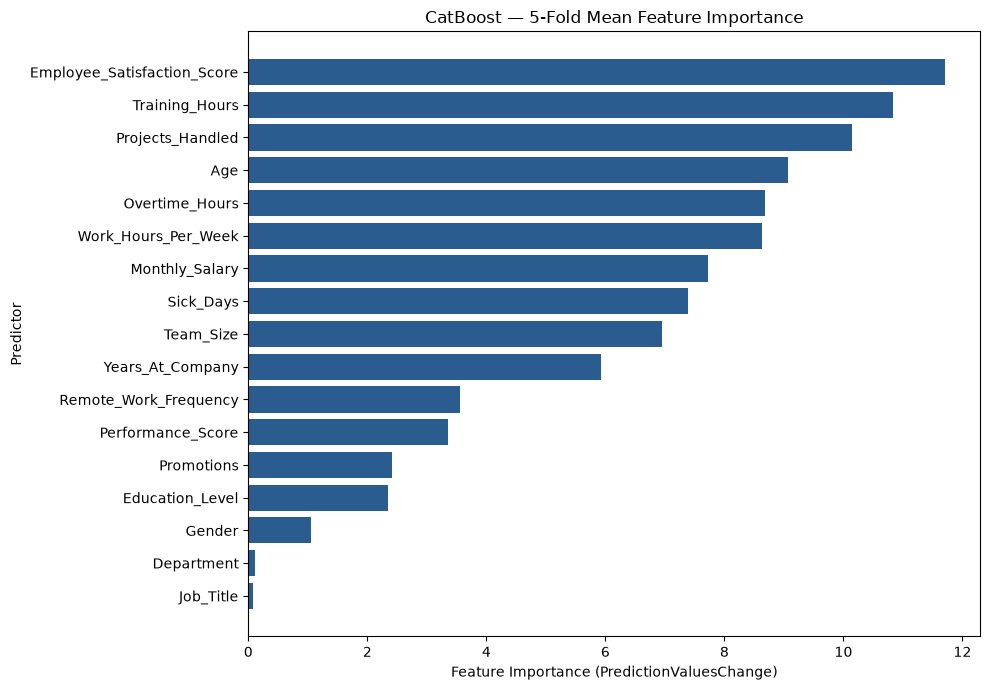

Feature importance exported.


In [30]:
mean_importance = np.mean(feature_importances, axis=0)
importance_df = pd.DataFrame({
    "feature": primary_features,
    "importance": mean_importance,
}).sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance_df["feature"], importance_df["importance"], color="#2b5c8f")
ax.set_title("CatBoost — 5-Fold Mean Feature Importance")
ax.set_xlabel("Feature Importance (PredictionValuesChange)")
ax.set_ylabel("Predictor")
fig.tight_layout()

# Save both named and EBM-compatible general files
importance_df_sorted = importance_df.sort_values("importance", ascending=False)
importance_df_sorted.to_csv(RESULTS_DIR / "catboost_feature_importance.csv", index=False)
importance_df_sorted.to_csv(RESULTS_DIR / "term_importances.csv", index=False)

fig_importance_path = RESULTS_DIR / "figure_01_catboost_feature_importance.png"
fig.savefig(fig_importance_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Feature importance exported.")

## 15. Save Artifacts

Export PR curves, confusion matrices, fold metric tables, OOF predictions, and the complete output manifest. Duplicate outputs with standard filenames (`oof_predictions.csv`, `fold_metrics.csv`, JSON summaries) are saved to guarantee full compatibility with `results/models/ebm/` and `11_model_comparison.ipynb`.

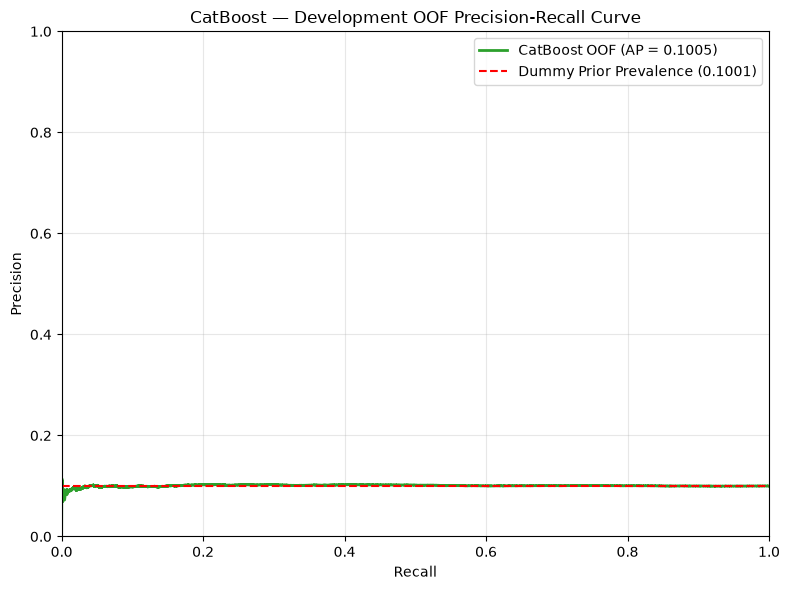

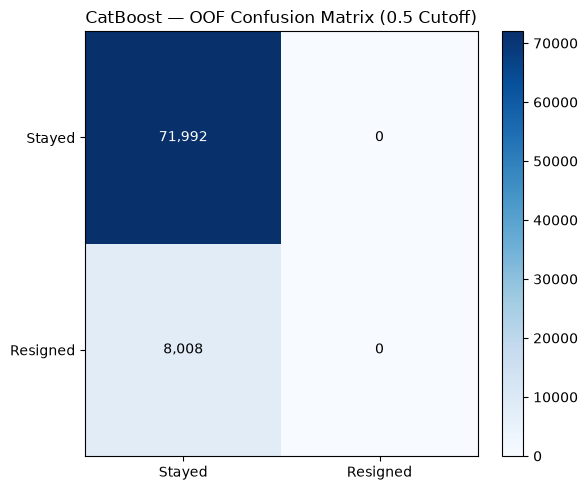

,file_name,relative_path,size_bytes,exists
0,catboost_development_model.cbm,models\catboost\catboost_development_model.cbm,732764,True
1,catboost_model_metadata.json,models\catboost\catboost_model_metadata.json,1578,True
2,catboost_oof_predictions.csv,results\models\catboost\catboost_oof_predictio...,3338592,True
3,oof_predictions.csv,results\models\catboost\oof_predictions.csv,3338592,True
4,catboost_fold_metrics.csv,results\models\catboost\catboost_fold_metrics.csv,754,True
5,fold_metrics.csv,results\models\catboost\fold_metrics.csv,754,True
6,catboost_summary_metrics.csv,results\models\catboost\catboost_summary_metri...,458,True
7,catboost_summary_metrics.json,results\models\catboost\catboost_summary_metri...,650,True
8,catboost_run_metadata.json,results\models\catboost\catboost_run_metadata....,1578,True
9,catboost_confusion_matrix.csv,results\models\catboost\catboost_confusion_mat...,91,True



All CatBoost artifacts exported successfully.


In [31]:
# 1. Precision-Recall Curve Plot
precisions, recalls, _ = precision_recall_curve(
    catboost_oof_df["y_true"],
    catboost_oof_df["y_probability"]
)
baseline_prev = dev_df["target"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recalls, precisions, label=f"CatBoost OOF (AP = {pooled_metrics['pr_auc']:.4f})", color="#2ca02c", lw=2)
ax.axhline(baseline_prev, color="red", linestyle="--", label=f"Dummy Prior Prevalence ({baseline_prev:.4f})")
ax.set_title("CatBoost — Development OOF Precision-Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.0])
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
fig.tight_layout()

pr_fig_path = RESULTS_DIR / "figure_02_catboost_precision_recall_curves.png"
fig.savefig(pr_fig_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Confusion Matrix Plot
cm = confusion_matrix(catboost_oof_df["y_true"], catboost_oof_df["y_pred_0_5"], labels=[0, 1])
cm_df = pd.DataFrame(
    cm,
    index=["Actual Stayed (0)", "Actual Resigned (1)"],
    columns=["Pred Stayed (0)", "Pred Resigned (1)"]
)
cm_df.to_csv(RESULTS_DIR / "catboost_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(cm, cmap="Blues", aspect="auto")
ax.set_title("CatBoost — OOF Confusion Matrix (0.5 Cutoff)")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Stayed", "Resigned"])
ax.set_yticklabels(["Stayed", "Resigned"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black" if cm[i, j] < cm.max() / 2 else "white")

fig.colorbar(cax)
fig.tight_layout()

cm_fig_path = RESULTS_DIR / "figure_03_catboost_confusion_matrix.png"
fig.savefig(cm_fig_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Save CSVs (both specific and general for pipeline compatibility)
catboost_oof_df.to_csv(RESULTS_DIR / "catboost_oof_predictions.csv", index=False)
catboost_oof_df.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

catboost_fold_metrics_df.to_csv(RESULTS_DIR / "catboost_fold_metrics.csv", index=False)
catboost_fold_metrics_df.to_csv(RESULTS_DIR / "fold_metrics.csv", index=False)

catboost_summary_metrics_df.to_csv(RESULTS_DIR / "catboost_summary_metrics.csv", index=False)

# 4. Save JSON summaries matching EBM conventions
with open(RESULTS_DIR / "catboost_summary_metrics.json", "w", encoding="utf-8") as f:
    json.dump(catboost_summary_metrics_df.iloc[0].to_dict(), f, indent=4)

with open(RESULTS_DIR / "catboost_run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

# 5. Remove .gitkeep if present
for folder in [MODELS_DIR, RESULTS_DIR]:
    gk = folder / ".gitkeep"
    if gk.exists():
        gk.unlink()

# 6. Build Manifest
tracked_files = [
    final_model_path,
    metadata_file,
    RESULTS_DIR / "catboost_oof_predictions.csv",
    RESULTS_DIR / "oof_predictions.csv",
    RESULTS_DIR / "catboost_fold_metrics.csv",
    RESULTS_DIR / "fold_metrics.csv",
    RESULTS_DIR / "catboost_summary_metrics.csv",
    RESULTS_DIR / "catboost_summary_metrics.json",
    RESULTS_DIR / "catboost_run_metadata.json",
    RESULTS_DIR / "catboost_confusion_matrix.csv",
    RESULTS_DIR / "catboost_feature_importance.csv",
    RESULTS_DIR / "term_importances.csv",
    fig_importance_path,
    pr_fig_path,
    cm_fig_path,
    RESULTS_DIR / "catboost_runtime_efficiency.csv",
]

manifest_df = pd.DataFrame([
    {
        "file_name": f.name,
        "relative_path": str(f.relative_to(PROJECT_ROOT)),
        "size_bytes": f.stat().st_size if f.exists() else 0,
        "exists": f.exists(),
    }
    for f in tracked_files
])

manifest_df.to_csv(RESULTS_DIR / "catboost_output_manifest.csv", index=False)
display(manifest_df)
print("\nAll CatBoost artifacts exported successfully.")

## 16. Summary

Document findings and readiness for stage 11 multi-model comparison.

### Key Observations & Next Steps

1. **Validation Performance vs Baseline**:
   - The primary metric, **PR-AUC**, must be evaluated against the `DummyClassifier(strategy="prior")` baseline (~0.1001).
   - If PR-AUC remains near 0.1001, CatBoost confirms the exploratory audit finding of weak out-of-sample signal, providing a defensible negative result for this model family.

2. **Accuracy Paradox at 0.5 Threshold**:
   - At the default 0.5 cutoff, the model classifies nearly all records as the majority class (`Stayed`), yielding ~89.99% accuracy but near-zero recall. This demonstrates the necessity of PR-AUC and rank-based evaluation over raw accuracy.

3. **Downstream Integration**:
   - Out-of-fold probabilities are saved to `results/models/catboost/catboost_oof_predictions.csv` for `11_model_comparison.ipynb`.
   - The refitted model `models/catboost/catboost_development_model.cbm` is stored and ready for probability calibration (`12_calibration.ipynb`) and retention prioritization (`14_retention_prioritization.ipynb`).

In [32]:
# ==========================================
# PHASE 3: POST-EXECUTION VALIDATION CHECKS
# ==========================================

# 1. Exact row count and uniqueness
assert len(catboost_oof_df) == 80_000, f"Expected 80,000 rows, got {len(catboost_oof_df)}"
assert not catboost_oof_df["Employee_ID"].duplicated().any(), "Duplicate Employee_IDs detected!"

# 2. Strict fold distribution (16,000 per fold)
assert set(catboost_oof_df["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert (catboost_oof_df["cv_fold"].value_counts() == 16_000).all()

# 3. Holdout isolation check (Zero contamination)
holdout_overlap = set(catboost_oof_df["Employee_ID"]).intersection(holdout_ids)
assert len(holdout_overlap) == 0, f"LEAKAGE DETECTED: {len(holdout_overlap)} holdout rows in OOF!"

# 4. Target distribution alignment
assert int((catboost_oof_df["y_true"] == 0).sum()) == 71_992
assert int((catboost_oof_df["y_true"] == 1).sum()) == 8_008

# 5. Probability range sanity
assert not catboost_oof_df["y_probability"].isna().any(), "NaN found in predictions!"
assert catboost_oof_df["y_probability"].between(0.0, 1.0).all(), "Probabilities outside [0, 1]!"

print(" All Phase 3 post-execution validation checks PASSED successfully!")

 All Phase 3 post-execution validation checks PASSED successfully!
